In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('main_data.csv')

In [4]:
df.head()

,Unnamed: 0,country,"fy2017, Dealing with construction permits","fy2019, Dealing with construction permits","fy2018, Dealing with construction permits"
0,0,AFG,33.70269,34.53602,34.53602
1,1,AGO,64.57157,65.32993,64.99177
2,2,ALB,52.60171,52.67715,52.64734
3,3,ARE,86.51006,89.75407,86.52729
4,4,ARG,48.96341,56.44015,49.26822


In [5]:
df.tail()

,Unnamed: 0,country,"fy2017, Dealing with construction permits","fy2019, Dealing with construction permits","fy2018, Dealing with construction permits"
186,186,XKX,50.29844,55.28702,52.87432
187,187,YEM,0.00000,0.00000,0.00000
188,188,ZAF,68.26741,68.32331,68.24925
189,189,ZMB,71.10859,72.09460,71.72488
190,190,ZWE,46.39289,60.00173,48.55427


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 191 entries, 0 to 190
Data columns (total 5 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Unnamed: 0                                 191 non-null    int64  
 1   country                                    191 non-null    object 
 2   fy2017, Dealing with construction permits  191 non-null    float64
 3   fy2019, Dealing with construction permits  191 non-null    float64
 4   fy2018, Dealing with construction permits  191 non-null    float64
dtypes: float64(3), int64(1), object(1)
memory usage: 7.6+ KB


In [7]:
df.shape

(191, 5)

In [8]:
df.columns

Index(['Unnamed: 0', 'country', 'fy2017, Dealing with construction permits',
       'fy2019, Dealing with construction permits',
       'fy2018, Dealing with construction permits'],
      dtype='object')

In [9]:
df.describe()

,Unnamed: 0,"fy2017, Dealing with construction permits","fy2019, Dealing with construction permits","fy2018, Dealing with construction permits"
count,191.0000,191.000000,191.000000,191.000000
mean,95.0000,63.269214,65.845667,64.770344
std,55.2811,16.622900,15.815424,15.707923
min,0.0000,0.000000,0.000000,0.000000
25%,47.5000,56.300935,59.640150,57.710025
50%,95.0000,66.694200,68.683240,67.943670
75%,142.5000,73.407800,75.182955,73.913715
max,190.0000,91.210020,93.467020,91.241050


In [10]:
df.drop("Unnamed: 0",axis=1,inplace=True)

In [21]:
df.head()

,country,"fy2017, Dealing with construction permits","fy2019, Dealing with construction permits","fy2018, Dealing with construction permits"
0,AFG,33.70269,34.53602,34.53602
1,AGO,64.57157,65.32993,64.99177
2,ALB,52.60171,52.67715,52.64734
3,ARE,86.51006,89.75407,86.52729
4,ARG,48.96341,56.44015,49.26822


In [11]:
X=df.iloc[:,1:]
X.head()

,"fy2017, Dealing with construction permits","fy2019, Dealing with construction permits","fy2018, Dealing with construction permits"
0,33.70269,34.53602,34.53602
1,64.57157,65.32993,64.99177
2,52.60171,52.67715,52.64734
3,86.51006,89.75407,86.52729
4,48.96341,56.44015,49.26822


In [12]:
## sharpest bend =largest angle

ELBOW METHOD

Elbow method is the most popular method that is used to determine the optimal value of k.

How it works?

Start with some K.

Calculate WCSS (Within Cluster Sum of squared errors) ie., for each of the cluster, it calculate the distance of individual data points from the centroid, then square it and sum it up. WCSS = WCSS1 + WCSS2 + ..... WCSSk

Take new value for K, repeat step2.

For each number of K, WCSS is calculated.

Find the elbow point. That is the optimal value of K.

As the number of K increases, the error reduces.

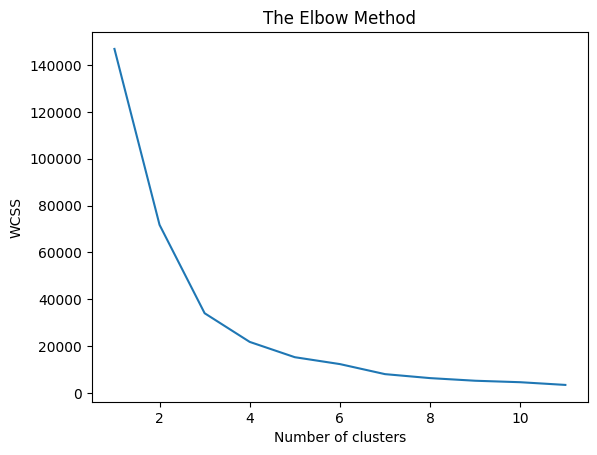

In [13]:
# Elbow Method
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings("ignore")
wcss=[]
for i in range (1,12):
    kmeans=KMeans(n_clusters=i,random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)
plt.plot(range(1,12),wcss)
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

In [14]:
## sharpest bend =largest angle from the output

MODEL BUILDING

In [15]:
# Initialise the model with K as 3
from sklearn.cluster import KMeans
model = KMeans(n_clusters=3, random_state=42)

#Training the model
model.fit(X)

,n_clusters,3
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [ ]:
label=model.labels_ #Retrieves the cluster assignments from the model.
label

array([0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0,
       0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0,
       1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 0, 0, 1, 1, 1, 1, 0, 2, 2, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0,
       1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1,
       2, 1, 0, 1, 1, 0, 1, 1, 1, 1, 2, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0,
       1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 2, 1, 1, 0], dtype=int32)

In [17]:
df.tail()

,country,"fy2017, Dealing with construction permits","fy2019, Dealing with construction permits","fy2018, Dealing with construction permits"
186,XKX,50.29844,55.28702,52.87432
187,YEM,0.00000,0.00000,0.00000
188,ZAF,68.26741,68.32331,68.24925
189,ZMB,71.10859,72.09460,71.72488
190,ZWE,46.39289,60.00173,48.55427


In [ ]:
model.cluster_centers_ #Shows the numerical center of each cluster.

array([[51.37082446, 56.48001462, 54.70178385],
       [72.63648108, 73.969857  , 73.22151008],
       [ 4.82308667,  4.82308667,  4.82308667]])

In [ ]:
from collections import Counter
Counter(label) #How many countries are in each group?

Counter({np.int32(1): 120, np.int32(0): 65, np.int32(2): 6})

In [20]:
new_point=[[15,40,100]] # A new observation
model.predict(new_point) # predicted label

array([0], dtype=int32)